# Coffee leaf disease classification: an end-to-end ML pipeline

**Use case.** Coffee is one of Rwanda's main export crops and a source of work for many young
people in rural areas. Leaf rust, leaf miner, brown leaf spot (Phoma) and Cercospora reduce yields,
and extension officers cannot visit every farm. This project builds a model that tells a farmer or
young agri-entrepreneur, from one phone photo of a leaf, whether the leaf is healthy or which biotic
stress dominates. The model is served by an API, monitored, and retrained when new labelled photos
arrive from the field.

This notebook covers:

1. Data acquisition (and why the first candidate dataset was rejected)
2. Exploratory analysis and feature interpretation
3. Preprocessing
4. Model creation: baseline, then transfer learning with optimisation
5. Model testing: accuracy, loss, precision, recall, F1, ROC-AUC, confusion matrix
6. Saving the model and the artefacts that retraining needs
7. Prediction functions
8. How retraining works

In [1]:
import gc, json, os, sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from src.config import CLASS_NAMES, CLASS_LABELS, IMG_SIZE, SEED, TRAIN_DIR, TEST_DIR, DATA_DIR, MODELS_DIR
from src import preprocessing, model as model_lib, insights

tf.keras.utils.set_random_seed(SEED)
# Keep memory modest on a laptop: few threads, small batches (peak stays well under 3 GB).
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
BATCH = 16

# Log memory after every cell to notebook_memory.log (helps keep training within a laptop's RAM).
_cell = {"n": 0}
def _log_memory(result):
    _cell["n"] += 1
    rss = int(open("/proc/self/statm").read().split()[1]) * os.sysconf("SC_PAGE_SIZE") // 2**20
    with open(ROOT / "notebook_memory.log", "a") as f:
        f.write(f"{time.strftime('%H:%M:%S')} cell {_cell['n']} rss {rss} MB\n")
get_ipython().events.register("post_run_cell", _log_memory)
sns.set_theme(style="whitegrid")
PALETTE = dict(zip(CLASS_NAMES, ["#8c6d31", "#2e7d32", "#5c6bc0", "#6d4c41", "#ef6c00"]))
print("TensorFlow", tf.__version__, "| image size", IMG_SIZE, "| classes", CLASS_NAMES)

TensorFlow 2.20.0 | image size 224 | classes ['cercospora', 'healthy', 'miner', 'phoma', 'rust']


## 1. Data acquisition

### First candidate: JMuBEN / JMuBEN2 (Kenya), rejected after an audit

JMuBEN and JMuBEN2 (Mendeley Data, 2021) advertise 58,555 Arabica coffee leaf images in five
classes. Before training on them I hashed every file (exact duplicates) and computed a
rotation/flip-invariant perceptual hash (near duplicates, because the authors augmented by
rotating and flipping). The result:

| Class | Files | Byte-unique | Distinct leaves (after rotations/flips) |
|---|---|---|---|
| Cercospora | 7,681 | 322 | 82 |
| Healthy | 18,984 | 63 | **17** |
| Leaf rust | 8,336 | 1,042 | 519 |
| Miner | 16,978 | 1,639 | 464 |
| Phoma | 6,571 | 691 | 181 |

Only about 1,260 distinct leaves exist, and only 17 healthy ones. A random train/test split would
put copies of the same leaf on both sides and report inflated accuracy. The leaf rust images also
come from a different camera at a different resolution, which would let a model learn the camera
instead of the disease. The dataset was not used.

### Chosen dataset: BRACOL (Brazil)

[BRACOL](https://data.mendeley.com/datasets/yy2k5y8mxg/1) (Krohling, Esgario & Ventura, 2019) has
smartphone photos of single Arabica leaves on a white background, labelled with the predominant
biotic stress by an expert. `scripts/acquire_data.py` downloads it from the Mendeley API. The archive
Mendeley serves is truncated (its SHA-256 matches Mendeley's published hash, but the zip has no
central directory), so the script reads the zip's local file headers directly and keeps every
complete image. Label 5 is undocumented by the authors and is dropped.

The split is stratified with a fixed seed: 20% test, and 10% of the remainder held back in
`data/new_data/`. The model never sees `new_data` here; it is uploaded through the web app to
demonstrate retraining on new field data.

In [2]:
summary = json.loads((DATA_DIR / "split_summary.json").read_text())
counts = pd.DataFrame({k: summary[k] for k in ["train", "test", "new_data"]}).loc[CLASS_NAMES]
counts["total"] = counts.sum(axis=1)
print("Skipped while reading the archive:", summary["skipped"])
counts.loc["total"] = counts.sum()
counts

Skipped while reading the archive: {'missing from truncated archive': 343, 'undocumented label 5': 62}


,train,test,new_data,total
cercospora,98,27,11,136
healthy,102,29,11,142
miner,182,51,20,253
phoma,249,69,28,346
rust,334,93,38,465
total,965,269,108,1342


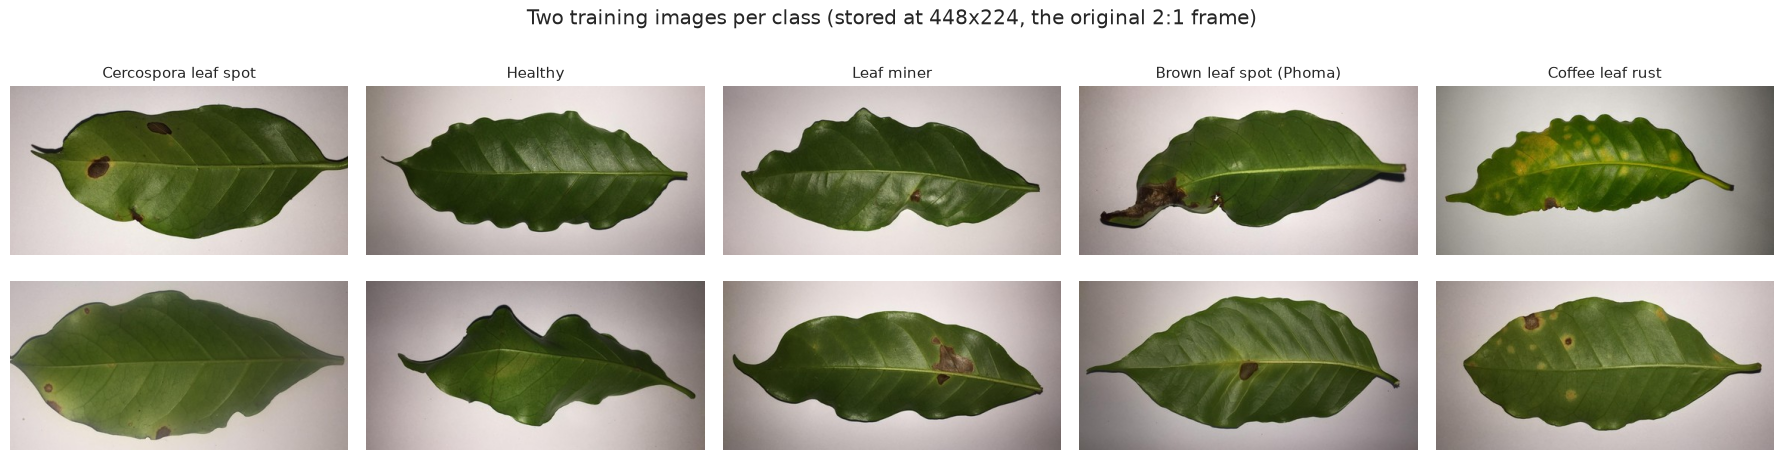

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(18, 5))
for col, cls in enumerate(CLASS_NAMES):
    files = sorted((TRAIN_DIR / cls).glob("*.jpg"))[:2]
    for row, f in enumerate(files):
        axes[row, col].imshow(plt.imread(f))
        axes[row, col].set_title(CLASS_LABELS[cls] if row == 0 else "", fontsize=11)
        axes[row, col].axis("off")
plt.suptitle("Two training images per class (stored at 448x224, the original 2:1 frame)")
plt.tight_layout(); plt.show()

## 2. Exploratory analysis: what distinguishes the classes?

Each photo is a single leaf on a white sheet, so the leaf can be separated from the background with a
simple colour rule (bright and unsaturated = background). `src/insights.py` measures five features on
the leaf pixels of every image:

* **leaf_area**: share of the frame covered by leaf
* **green_ratio**: share of leaf pixels with a green hue (healthy tissue)
* **lesion_ratio**: share of leaf pixels with a yellow, orange or brown hue (symptoms)
* **brightness**: mean HSV value of the leaf
* **texture**: mean gradient magnitude on the leaf (spots, pustules and mines add edges)

In [4]:
features = insights.compute_feature_table()
stats = insights.build_dataset_stats(features)   # also saved for the web dashboard
features.groupby("class")[insights.FEATURES].mean().round(3).loc[CLASS_NAMES]

,leaf_area,green_ratio,lesion_ratio,brightness,texture
class,,,,,
cercospora,0.360,0.792,0.029,0.433,6.758
healthy,0.378,0.878,0.002,0.381,5.868
miner,0.391,0.756,0.042,0.388,5.956
phoma,0.302,0.805,0.054,0.435,8.995
rust,0.398,0.774,0.047,0.444,6.662


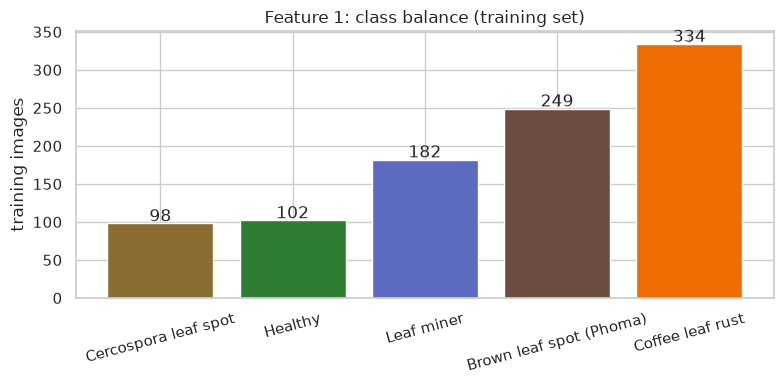

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
c = features[features.split == "train"]["class"].value_counts().reindex(CLASS_NAMES)
ax.bar([CLASS_LABELS[k] for k in c.index], c.values, color=[PALETTE[k] for k in c.index])
for i, v in enumerate(c.values):
    ax.text(i, v + 3, str(v), ha="center")
ax.set_ylabel("training images"); ax.set_title("Feature 1: class balance (training set)")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

**Feature 1, class balance.** Rust is the largest class (334 training images) and Cercospora and
healthy the smallest (about 100 each), a 3.4:1 imbalance. A model trained naively would lean towards
predicting rust. This is why training uses **class weights** and why the evaluation reports
**macro** precision, recall and F1 (each class counts equally) next to plain accuracy.

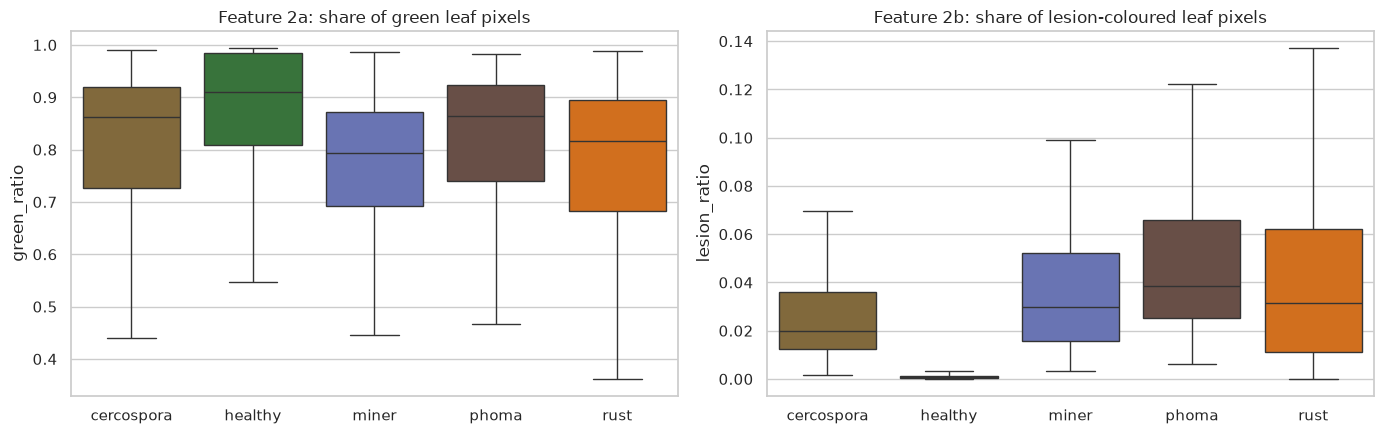

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, f, title in [(axes[0], "green_ratio", "Feature 2a: share of green leaf pixels"),
                     (axes[1], "lesion_ratio", "Feature 2b: share of lesion-coloured leaf pixels")]:
    sns.boxplot(data=features, x="class", y=f, order=CLASS_NAMES, hue="class", palette=PALETTE,
                legend=False, ax=ax, showfliers=False)
    ax.set_title(title); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Feature 2, leaf colour.** Healthy leaves are the greenest (median green share about 0.88) and have
almost no lesion-coloured pixels (mean 0.2% of the leaf). Every diseased class has a lower green share
and a visible lesion tail: rust (orange pustules) and brown leaf spot (dark brown patches) have the
largest lesion shares. **Story:** colour alone separates *healthy vs diseased* well, but the diseased
classes overlap heavily on colour, so the model needs shape and texture, not just colour, to tell the
diseases apart. That motivates a convolutional network rather than a colour-histogram classifier.

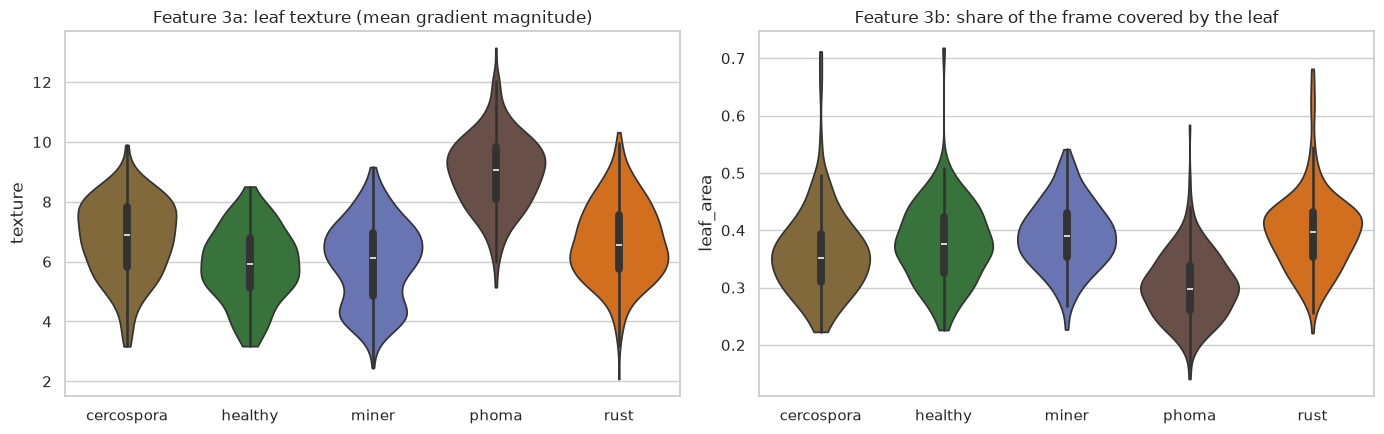

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.violinplot(data=features, x="class", y="texture", order=CLASS_NAMES, hue="class", palette=PALETTE,
               legend=False, ax=axes[0], cut=0)
axes[0].set_title("Feature 3a: leaf texture (mean gradient magnitude)"); axes[0].set_xlabel("")
sns.violinplot(data=features, x="class", y="leaf_area", order=CLASS_NAMES, hue="class", palette=PALETTE,
               legend=False, ax=axes[1], cut=0)
axes[1].set_title("Feature 3b: share of the frame covered by the leaf"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

**Feature 3, texture and leaf size.** Brown leaf spot (Phoma) leaves stand out on both: they have the
highest texture (mean about 9.0 against 5.9 for healthy) and the smallest leaf area (about 30% of the
frame against 36-40% for the other classes). Phoma kills tissue at the leaf margins and tips, which
makes leaves smaller and ragged and adds dark, sharp-edged patches. Leaf miner leaves have texture close
to healthy ones because mines are pale, smooth trails rather than sharp spots. **Story:** a damaged
outline and high texture point to Phoma; a pale smooth trail on an otherwise green leaf points to miner.

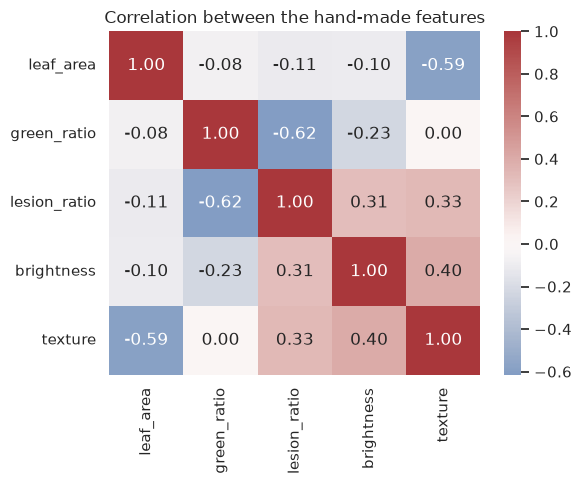

In [8]:
corr = features[insights.FEATURES].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation between the hand-made features"); plt.tight_layout(); plt.show()

Green share and lesion share are strongly negatively correlated, as expected: lesion pixels replace
green ones. Texture is only weakly tied to colour, so it carries extra information. Together these
hand-made features give a partial separation of the classes; the CNN below learns richer features
of the same kind directly from pixels.

## 3. Preprocessing

`src/preprocessing.load_image` is the single preprocessing function used for training, for uploaded
retraining images and for predictions:

1. Decode, and apply the EXIF orientation that phones store.
2. Convert to RGB (drops alpha channels and greyscale modes).
3. Rotate portrait photos to landscape, because every leaf in the dataset lies horizontally.
4. Resize to 224 x 224 (the MobileNetV2 input size).
5. Inside the model: rescale pixels from [0, 255] to [-1, 1], the range MobileNetV2 was trained on.

**Augmentation** (training only, inside the model so it runs on the fly): random horizontal and
vertical flips, rotation (up to 8% of a turn), zoom (15%), brightness (15%) and contrast (15%). Field
photos vary in angle and lighting, and with about 1,000 training images augmentation is the main
defence against overfitting.

A stratified 15% of the training set is used for validation (early stopping and learning-rate
decisions). The test set is only used for the final evaluation.

In [9]:
from sklearn.model_selection import train_test_split

x_all, y_all = preprocessing.load_folder(TRAIN_DIR)
x_test, y_test = preprocessing.load_folder(TEST_DIR)
x_train, x_val, y_train, y_val = train_test_split(x_all, y_all, test_size=0.15, stratify=y_all, random_state=SEED)
print("train", x_train.shape, "val", x_val.shape, "test", x_test.shape, "dtype", x_train.dtype)

train_ds = preprocessing.make_tf_dataset(x_train, y_train, batch_size=BATCH, shuffle=True)
val_ds = preprocessing.make_tf_dataset(x_val, y_val, batch_size=BATCH)
test_ds = preprocessing.make_tf_dataset(x_test, y_test, batch_size=BATCH)

from src.retrain import class_weights
cw = class_weights(y_train)
print("class weights:", {CLASS_NAMES[k]: round(v, 2) for k, v in cw.items()})

train (820, 224, 224, 3) val (145, 224, 224, 3) test (269, 224, 224, 3) dtype uint8


E0000 00:00:1795718828.216508 3972619 cuda_executor.cc:1309] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1795718828.220968 3972619 gpu_device.cc:2342] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


class weights: {'cercospora': 1.98, 'healthy': 1.89, 'miner': 1.06, 'phoma': 0.78, 'rust': 0.58}


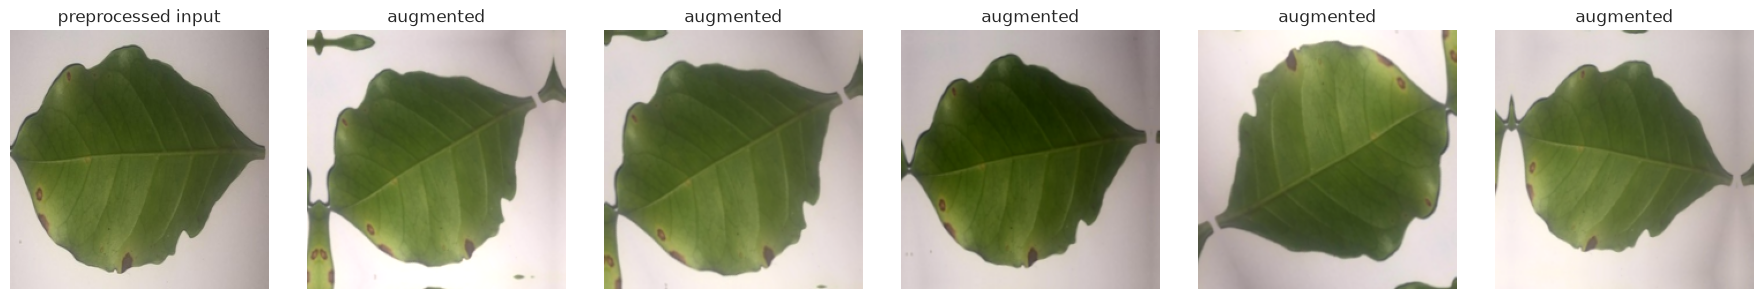

In [10]:
aug = preprocessing.augmentation_layers()
sample = x_train[:1].astype("float32")
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
axes[0].imshow(sample[0].astype("uint8")); axes[0].set_title("preprocessed input")
for ax in axes[1:]:
    ax.imshow(np.clip(aug(sample, training=True)[0].numpy(), 0, 255).astype("uint8")); ax.set_title("augmented")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Model creation

### 4.1 Baseline: logistic regression on frozen ImageNet features

A quick reference point: pass each image once through MobileNetV2 (ImageNet weights, no training),
average-pool to a 1280-d vector and fit a logistic regression. Anything we build later has to beat this.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

backbone0 = model_lib.build_backbone()
emb = lambda x: np.concatenate([backbone0(x[i:i+BATCH].astype("float32"), training=False).numpy() for i in range(0, len(x), BATCH)])
t = time.time()
f_train, f_test = emb(x_all), emb(x_test)
baseline = LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced").fit(f_train, y_all)
pred = baseline.predict(f_test)
baseline_scores = {"accuracy": accuracy_score(y_test, pred), "f1_macro": f1_score(y_test, pred, average="macro")}
print({k: round(v, 4) for k, v in baseline_scores.items()}, f"({time.time()-t:.0f}s)")
del backbone0, f_train, f_test; gc.collect()   # free the extra network before training

{'accuracy': 0.7955, 'f1_macro': 0.7401} (37s)


31807

### 4.2 Transfer learning with MobileNetV2, optimised

Architecture (`src/model.py`):

`image -> augmentation -> rescale to [-1, 1] -> MobileNetV2 (ImageNet) -> global average pooling -> dropout 0.3 -> dense softmax (5, L2 1e-4)`

Optimisation techniques used:

| Technique | Where |
|---|---|
| Pre-trained model (transfer learning) | MobileNetV2 with ImageNet weights |
| Regularisation | dropout 0.3, L2 weight decay 1e-4 on the classifier, data augmentation |
| Optimiser | Adam; phase 2 uses a 10x smaller learning rate |
| Early stopping | stops on validation loss and restores the best weights |
| Learning-rate schedule | ReduceLROnPlateau halves the rate when validation loss stalls |
| Class weights | inverse class frequency, against the 3.4:1 imbalance |
| Fine-tuning | phase 2 unfreezes the top of MobileNetV2 |

**Phase 1:** the backbone is frozen and only the classification head trains (fast, avoids destroying
the pre-trained features with large early gradients).

In [12]:
model = model_lib.build_model(augment=True)
backbone, head = model_lib.split_model(model)

def callbacks(patience):
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)]

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t = time.time()
h1 = model.fit(train_ds, validation_data=val_ds, epochs=30, class_weight=cw, callbacks=callbacks(5), verbose=2)
print(f"phase 1: {len(h1.history['loss'])} epochs in {time.time()-t:.0f}s")

Epoch 1/30


/home/rca/projects/personal/learning/alu-mlp-summative/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


52/52 - 17s - 324ms/step - accuracy: 0.3366 - loss: 1.7042 - val_accuracy: 0.5793 - val_loss: 1.0177 - learning_rate: 0.0010


Epoch 2/30


52/52 - 15s - 292ms/step - accuracy: 0.5524 - loss: 1.1567 - val_accuracy: 0.7034 - val_loss: 0.8824 - learning_rate: 0.0010


Epoch 3/30


... (28 outputs left out)

52/52 - 14s - 261ms/step - accuracy: 0.8037 - loss: 0.5631 - val_accuracy: 0.7517 - val_loss: 0.6332 - learning_rate: 5.0000e-04


Epoch 18/30


52/52 - 14s - 262ms/step - accuracy: 0.7915 - loss: 0.5868 - val_accuracy: 0.7448 - val_loss: 0.6380 - learning_rate: 2.5000e-04


phase 1: 18 epochs in 268s


**Phase 2: fine-tuning.** Unfreeze the last 30 layers of MobileNetV2 (the high-level feature blocks)
and keep training with a 10x smaller learning rate. BatchNorm layers stay in inference mode so their
statistics are not disturbed by small batches.

In [13]:
base = backbone.get_layer("mobilenetv2_1.00_224")
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
print("trainable weights:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))

model.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t = time.time()
h2 = model.fit(train_ds, validation_data=val_ds, epochs=25, class_weight=cw, callbacks=callbacks(6), verbose=2)
print(f"phase 2: {len(h2.history['loss'])} epochs in {time.time()-t:.0f}s")

trainable weights: 1517125
Epoch 1/25


52/52 - 19s - 370ms/step - accuracy: 0.6963 - loss: 0.8455 - val_accuracy: 0.6966 - val_loss: 0.6976 - learning_rate: 1.0000e-04


Epoch 2/25


52/52 - 16s - 305ms/step - accuracy: 0.7805 - loss: 0.6108 - val_accuracy: 0.7379 - val_loss: 0.6699 - learning_rate: 1.0000e-04


Epoch 3/25


52/52 - 15s - 296ms/step - accuracy: 0.7890 - loss: 0.5842 - val_accuracy: 0.7931 - val_loss: 0.5576 - learning_rate: 1.0000e-04


... (27 outputs left out)

52/52 - 15s - 297ms/step - accuracy: 0.9451 - loss: 0.1419 - val_accuracy: 0.8621 - val_loss: 0.4579 - learning_rate: 2.5000e-05


Epoch 18/25


52/52 - 16s - 310ms/step - accuracy: 0.9549 - loss: 0.1413 - val_accuracy: 0.8690 - val_loss: 0.4332 - learning_rate: 2.5000e-05


phase 2: 18 epochs in 312s


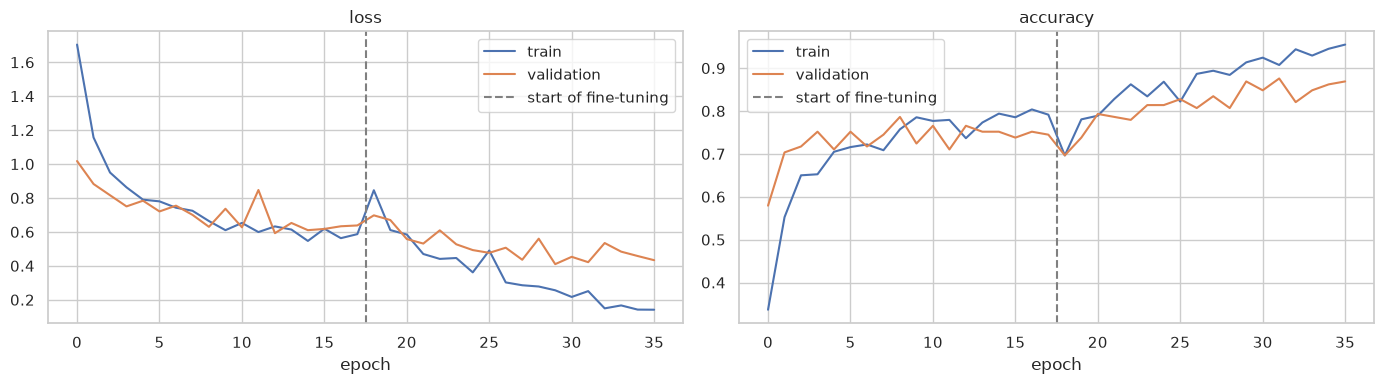

In [14]:
hist = {k: h1.history[k] + h2.history[k] for k in ["loss", "val_loss", "accuracy", "val_accuracy"]}
split = len(h1.history["loss"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, m in zip(axes, ["loss", "accuracy"]):
    ax.plot(hist[m], label="train"); ax.plot(hist["val_" + m], label="validation")
    ax.axvline(split - 0.5, color="grey", ls="--", label="start of fine-tuning")
    ax.set_title(m); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

## 5. Model testing on the held-out test set

The inference model is rebuilt from the trained backbone and head, without the augmentation layers.
Metrics: accuracy, cross-entropy loss, macro precision, macro recall, macro F1, one-vs-rest ROC-AUC,
the per-class report and the confusion matrix.

In [15]:
from sklearn.metrics import roc_auc_score, classification_report, ConfusionMatrixDisplay

for layer in base.layers:
    layer.trainable = False
infer = model_lib.assemble(backbone, head)
del train_ds, val_ds, model; gc.collect()   # training-only objects are no longer needed

def predict_in_batches(m, x):
    return np.concatenate([m(x[i:i+BATCH].astype("float32"), training=False).numpy() for i in range(0, len(x), BATCH)])

probs = predict_in_batches(infer, x_test)
metrics = model_lib.evaluate_predictions(y_test, probs)
metrics["roc_auc_ovr"] = round(float(roc_auc_score(y_test, probs, multi_class="ovr", average="macro")), 4)

table = pd.DataFrame({
    "Baseline (logistic regression on frozen features)": [baseline_scores["accuracy"], None, None, None, baseline_scores["f1_macro"], None],
    "MobileNetV2 fine-tuned": [metrics[k] for k in ["accuracy", "loss", "precision", "recall", "f1", "roc_auc_ovr"]],
}, index=["accuracy", "loss", "precision (macro)", "recall (macro)", "F1 (macro)", "ROC-AUC (macro OvR)"]).round(4)
table

,Baseline (logistic regression on frozen features),MobileNetV2 fine-tuned
accuracy,0.7955,0.8216
loss,NaN,0.4156
precision (macro),NaN,0.7842
recall (macro),NaN,0.7671
F1 (macro),0.7401,0.7736
ROC-AUC (macro OvR),NaN,0.9654


                         precision    recall  f1-score   support

   Cercospora leaf spot      0.355     0.407     0.379        27
                Healthy      0.929     0.897     0.912        29
             Leaf miner      0.814     0.686     0.745        51
Brown leaf spot (Phoma)      1.000     0.942     0.970        69
       Coffee leaf rust      0.824     0.903     0.862        93

               accuracy                          0.822       269
              macro avg      0.784     0.767     0.774       269
           weighted avg      0.831     0.822     0.824       269



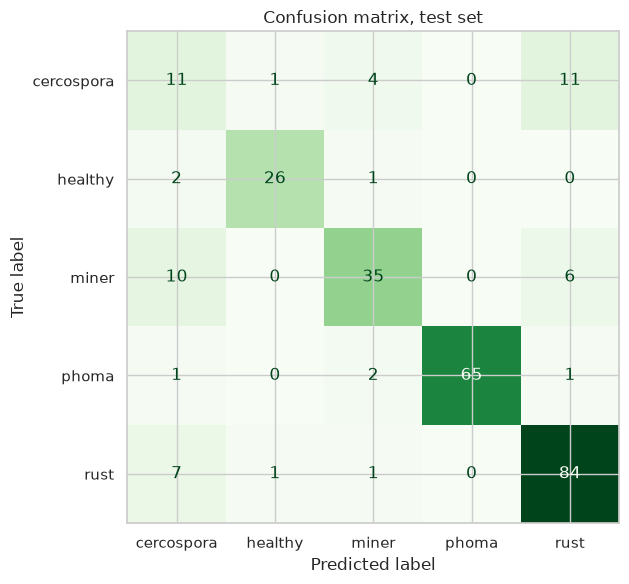

In [16]:
print(classification_report(y_test, probs.argmax(1), target_names=[CLASS_LABELS[c] for c in CLASS_NAMES], digits=3))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(np.array(metrics["confusion_matrix"]), display_labels=CLASS_NAMES).plot(ax=ax, cmap="Greens", colorbar=False)
ax.set_title("Confusion matrix, test set"); plt.tight_layout(); plt.show()

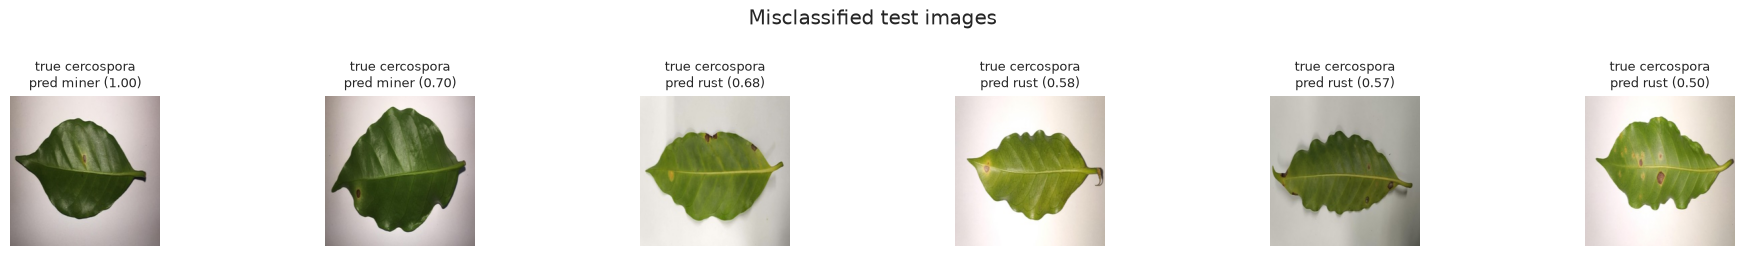

In [17]:
wrong = np.where(probs.argmax(1) != y_test)[0][:6]
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(3.2 * len(wrong), 2.6))
    for ax, i in zip(np.atleast_1d(axes), wrong):
        ax.imshow(x_test[i]); ax.axis("off")
        ax.set_title(f"true {CLASS_NAMES[y_test[i]]}\npred {CLASS_NAMES[probs[i].argmax()]} ({probs[i].max():.2f})", fontsize=9)
    plt.suptitle("Misclassified test images"); plt.tight_layout(); plt.show()

Many BRACOL leaves carry more than one stress (for example rust pustules next to Phoma patches) and
are labelled with the **predominant** one, so some errors are between two stresses that are both
present on the leaf. That is a limitation of single-label classification, not only of the model.

## 6. Saving the model and the retraining artefacts

* `models/coffee_leaf_model.keras` (native Keras format, loaded by the API) and
  `models/coffee_leaf_model.h5` (HDF5 copy, as the brief asks for)
* `models/model_metadata.json`: version, classes, test metrics, history of versions
* `models/replay_embeddings.npz` and `models/test_embeddings.npz`: backbone features of the training
  and test images. Retraining continues training the head on new + replay features and scores it on
  the same test features, so a retrain on a small cloud instance only runs the backbone on new images.

In [18]:
from src.config import REPLAY_EMB_PATH, TEST_EMB_PATH, METADATA_PATH
from src.retrain import embed, save_embeddings

if METADATA_PATH.exists():
    METADATA_PATH.unlink()   # start the version history at v1 for a fresh training run
meta = model_lib.save_model(infer, metrics, extra={"trained_on": "notebook", "baseline": baseline_scores})
save_embeddings(REPLAY_EMB_PATH, embed(backbone, x_all), y_all)
save_embeddings(TEST_EMB_PATH, embed(backbone, x_test), y_test)
for p in sorted(MODELS_DIR.iterdir()):
    print(f"{p.name:32s} {p.stat().st_size/1e6:6.2f} MB")
print("saved model version", meta["version"])

# Free everything used for training before the prediction demo reloads the saved model.
del infer, backbone, head, base, x_train, x_val, x_all, h1, h2
tf.keras.backend.clear_session(); gc.collect()

coffee_leaf_model.h5               9.42 MB
coffee_leaf_model.keras            9.66 MB
dataset_stats.json                 0.01 MB
model_metadata.json                0.00 MB
replay_embeddings.npz              1.44 MB
test_embeddings.npz                0.40 MB
saved model version 1


0

## 7. Prediction functions

`src/prediction.Predictor` loads the saved model once and predicts from raw image bytes, exactly as
the API does. Below: the reloaded model predicts images it has never seen, from `data/new_data`.

E0000 00:00:1795719546.948959 3998607 cuda_executor.cc:1309] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1795719546.954307 3998607 gpu_device.cc:2342] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


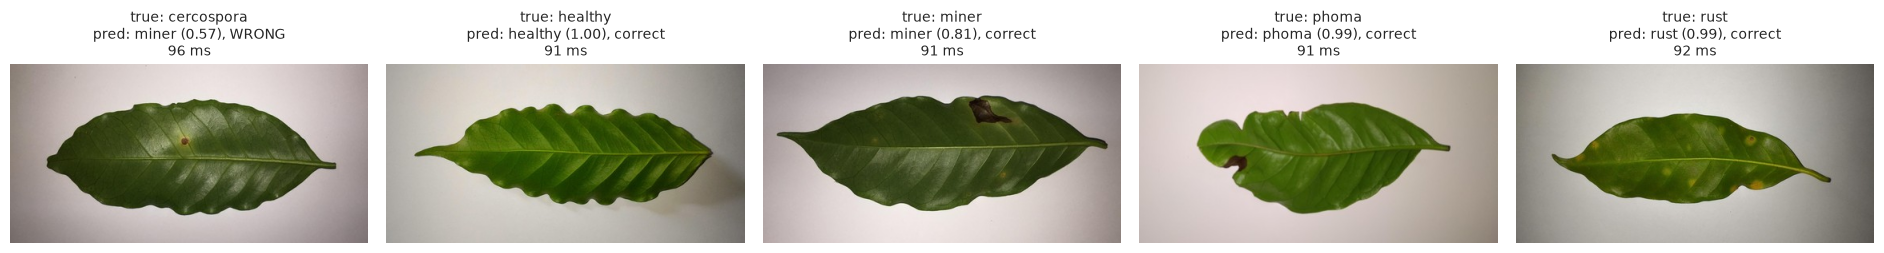

In [2]:
from src.prediction import Predictor

predictor = Predictor()
new_dir = DATA_DIR / "new_data"
samples = [sorted((new_dir / c).glob("*.jpg"))[0] for c in CLASS_NAMES]
fig, axes = plt.subplots(1, 5, figsize=(19, 3.2))
for ax, path in zip(axes, samples):
    t = time.time()
    result = predictor.predict_bytes(path.read_bytes())
    ms = (time.time() - t) * 1000
    ax.imshow(plt.imread(path)); ax.axis("off")
    ok = "correct" if result["class"] == path.parent.name else "WRONG"
    ax.set_title(f"true: {path.parent.name}\npred: {result['class']} ({result['confidence']:.2f}), {ok}\n{ms:.0f} ms", fontsize=10)
plt.tight_layout(); plt.show()

In [3]:
x_new, y_new = preprocessing.load_folder(new_dir)
p_new = predictor.predict_array(x_new.astype("float32"))
print("accuracy on the 108 held-back new_data images:", round(float((p_new.argmax(1) == y_new).mean()), 4))

accuracy on the 108 held-back new_data images: 0.8056


## 8. Retraining

Retraining is implemented in `src/retrain.py` and exposed by the API (`POST /retrain`) and the web app:

1. **Upload:** the user uploads labelled images (several files, or a zip with one folder per class).
   Each image is validated and **saved to the database** (`uploads` table, image bytes plus label).
2. **Preprocessing:** the uploaded images go through the same `load_image` function as above.
3. **Retraining from the existing model:** the current saved model is loaded and used as the
   pre-trained starting point. Its backbone turns the new images into features and its existing head
   continues training (Adam, early stopping, class weights) on new + replay features.
4. **Evaluation and promotion:** test accuracy before and after is recorded in `training_runs`. The new
   version is saved and hot-swapped into the running API only if accuracy does not drop by more than one point.

**Triggers:** a *Retrain* button (manual), and an automatic trigger that starts a run once the number
of unused uploaded images reaches `RETRAIN_THRESHOLD` (default 50).